Import thr lib

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.float_format", "{:.3f}".format)

# Visualization style
sns.set_theme(style="whitegrid")

load the dataset



In [4]:
df = pd.read_csv("pcos.csv")

print("Dataset loaded successfully!")

Dataset loaded successfully!


Check the dataset's dimensions

In [5]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])
print("Dataset shape:", df.shape)

Number of rows: 124959
Number of columns: 17
Dataset shape: (124959, 17)


display the top 5 records

In [6]:
df.head()

,Country,Age,BMI,Menstrual Regularity,Hirsutism,Acne Severity,Family History of PCOS,Insulin Resistance,Lifestyle Score,Stress Levels,Urban/Rural,Socioeconomic Status,Awareness of PCOS,Fertility Concerns,Undiagnosed PCOS Likelihood,Ethnicity,Diagnosis
0,Madagascar,26.000,Overweight,Regular,Yes,Severe,Yes,Yes,2.000,Low,Rural,High,Yes,No,0.108,Hispanic,Yes
1,Vietnam,16.000,Underweight,Regular,Yes,NaN,No,Yes,4.000,High,Rural,Middle,Yes,No,0.157,Other,No
2,Somalia,41.000,Normal,Regular,No,Moderate,No,No,7.000,Medium,Urban,Middle,Yes,Yes,0.203,Other,No
3,Malawi,27.000,Normal,Irregular,No,Mild,No,No,10.000,Low,Urban,High,Yes,No,0.074,Caucasian,Yes
4,France,26.000,Overweight,Irregular,Yes,NaN,No,No,7.000,Medium,Urban,Middle,No,No,0.229,Caucasian,No


In [7]:
df.sample(10, random_state=42)

,Country,Age,BMI,Menstrual Regularity,Hirsutism,Acne Severity,Family History of PCOS,Insulin Resistance,Lifestyle Score,Stress Levels,Urban/Rural,Socioeconomic Status,Awareness of PCOS,Fertility Concerns,Undiagnosed PCOS Likelihood,Ethnicity,Diagnosis
17765,Myanmar,27.000,Overweight,Regular,Yes,NaN,No,No,9.000,High,Urban,Middle,Yes,Yes,0.083,Other,No
6391,Saudi Arabia,34.000,Normal,Irregular,No,Severe,Yes,No,6.000,Medium,Urban,High,Yes,Yes,0.094,Other,Yes
116546,South Africa,29.000,Overweight,Regular,No,NaN,No,Yes,10.000,Low,Rural,Middle,No,Yes,0.056,Other,No
21192,Pakistan,36.000,Obese,Regular,Yes,NaN,No,Yes,9.000,Medium,Rural,Middle,No,Yes,0.241,Caucasian,No
92527,South Korea,44.000,Normal,Regular,Yes,NaN,Yes,No,1.000,Medium,Urban,Low,No,No,0.224,Other,No
27872,Burundi,17.000,Overweight,Irregular,No,NaN,Yes,No,10.000,Low,Rural,Middle,No,No,0.138,African,Yes
65315,Malaysia,30.000,Overweight,Regular,No,NaN,No,No,2.000,High,Urban,Middle,No,Yes,0.170,Caucasian,No
32335,Bangladesh,39.000,Obese,Regular,Yes,NaN,No,No,8.000,Medium,Rural,Low,Yes,Yes,0.078,Asian,No
109625,Yemen,28.000,Overweight,Regular,No,Mild,Yes,No,8.000,Medium,Urban,High,Yes,Yes,0.068,Asian,No
82058,Malawi,27.000,Underweight,Regular,No,Mild,No,No,5.000,Medium,Urban,Middle,Yes,Yes,0.168,Asian,No


In [8]:
print("Total columns:", len(df.columns))

for index, column in enumerate(df.columns, start=1):
    print(f"{index}. {column}")

Total columns: 17
1. Country
2. Age
3. BMI
4. Menstrual Regularity
5. Hirsutism
6. Acne Severity
7. Family History of PCOS
8. Insulin Resistance
9. Lifestyle Score
10. Stress Levels
11. Urban/Rural
12. Socioeconomic Status
13. Awareness of PCOS
14. Fertility Concerns
15. Undiagnosed PCOS Likelihood
16. Ethnicity
17. Diagnosis


In [9]:
df.info()  #understand the datatypes

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 124959 entries, 0 to 124958
Data columns (total 17 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Country                      124959 non-null  object 
 1   Age                          124959 non-null  float64
 2   BMI                          124959 non-null  object 
 3   Menstrual Regularity         124959 non-null  object 
 4   Hirsutism                    124959 non-null  object 
 5   Acne Severity                64874 non-null   object 
 6   Family History of PCOS       124959 non-null  object 
 7   Insulin Resistance           124959 non-null  object 
 8   Lifestyle Score              124959 non-null  float64
 9   Stress Levels                124959 non-null  object 
 10  Urban/Rural                  124959 non-null  object 
 11  Socioeconomic Status         124959 non-null  object 
 12  Awareness of PCOS            124959 non-null  object 
 13 

Generate descriptive statistics

In [10]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Age,124959.000,32.005,10.065,15.000,23.000,32.000,41.000,50.000
Lifestyle Score,124959.000,5.505,2.874,1.000,3.000,6.000,8.000,10.000
Undiagnosed PCOS Likelihood,124959.000,0.160,0.088,0.010,0.101,0.153,0.204,0.988


In [11]:
df.describe(include="object").T

,count,unique,top,freq
Country,124959,77,Burkina Faso,1750
BMI,124959,4,Normal,62573
Menstrual Regularity,124959,2,Regular,86915
Hirsutism,124959,2,No,74706
Acne Severity,64874,3,Mild,38356
Family History of PCOS,124959,2,No,87363
Insulin Resistance,124959,2,No,93535
Stress Levels,124959,3,Medium,62331
Urban/Rural,124959,2,Urban,87529
Socioeconomic Status,124959,3,Middle,62330


count missing values

In [12]:
missing_count = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage": (missing_count / len(df)) * 100
})

missing_summary = missing_summary.sort_values(
    by="Missing Percentage",
    ascending=False
)

missing_summary

,Missing Count,Missing Percentage
Acne Severity,60085,48.084
Diagnosis,1,0.001
Ethnicity,1,0.001
Country,0,0.000
Age,0,0.000
Hirsutism,0,0.000
Family History of PCOS,0,0.000
Menstrual Regularity,0,0.000
BMI,0,0.000
Lifestyle Score,0,0.000


Visualize missing values

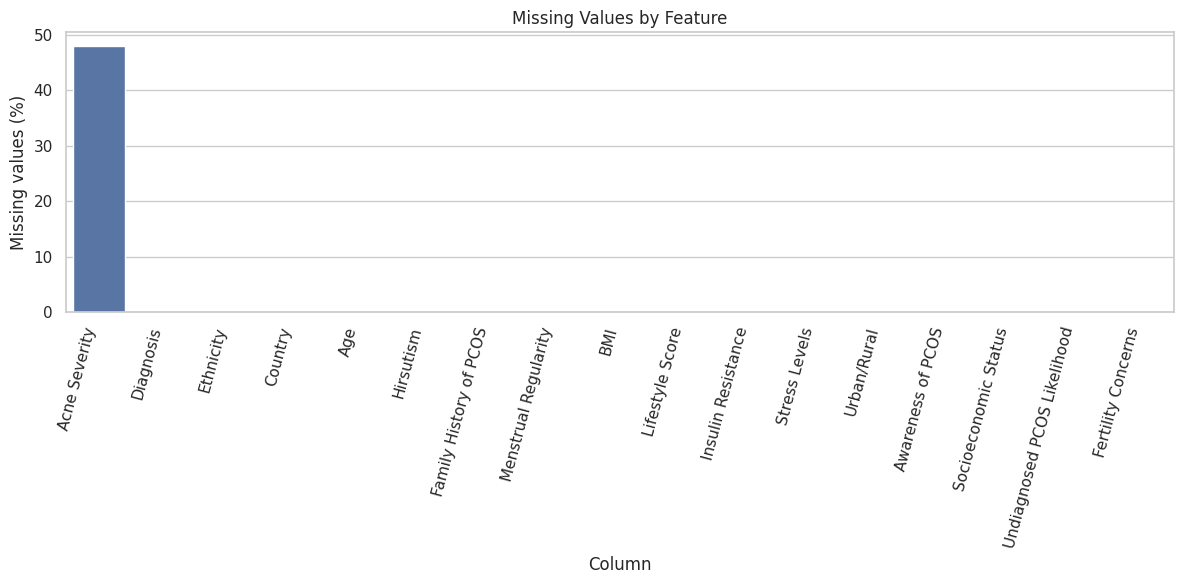

In [13]:
plt.figure(figsize=(12, 6))

sns.barplot(
    x=missing_summary.index,
    y=missing_summary["Missing Percentage"]
)

plt.xticks(rotation=75, ha="right")
plt.ylabel("Missing values (%)")
plt.xlabel("Column")
plt.title("Missing Values by Feature")
plt.tight_layout()
plt.show()

check duplicate records

In [14]:
duplicate_count = df.duplicated().sum()

print("Duplicate rows:", duplicate_count)

Duplicate rows: 0


Check unique values

In [15]:
unique_summary = pd.DataFrame({
    "Unique Values": df.nunique(dropna=True),
    "Data Type": df.dtypes.astype(str)
})

unique_summary

,Unique Values,Data Type
Country,77,object
Age,36,float64
BMI,4,object
Menstrual Regularity,2,object
Hirsutism,2,object
Acne Severity,3,object
Family History of PCOS,2,object
Insulin Resistance,2,object
Lifestyle Score,10,float64
Stress Levels,3,object


Check the target column

In [16]:
target_column = "Diagnosis"

print("Target column:", target_column)
print("\nTarget values:")
print(df[target_column].value_counts(dropna=False))

print("\nTarget data type:")
print(df[target_column].dtype)

Target column: Diagnosis

Target values:
Diagnosis
No     109865
Yes     15093
NaN         1
Name: count, dtype: int64

Target data type:
object


Analyze class distribution

In [17]:
target_counts = df[target_column].value_counts(dropna=False)

target_percentages = (
    df[target_column]
    .value_counts(normalize=True, dropna=False)
    .mul(100)
)

target_summary = pd.DataFrame({
    "Count": target_counts,
    "Percentage": target_percentages
})

target_summary

,Count,Percentage
Diagnosis,,
No,109865,87.921
Yes,15093,12.078
NaN,1,0.001


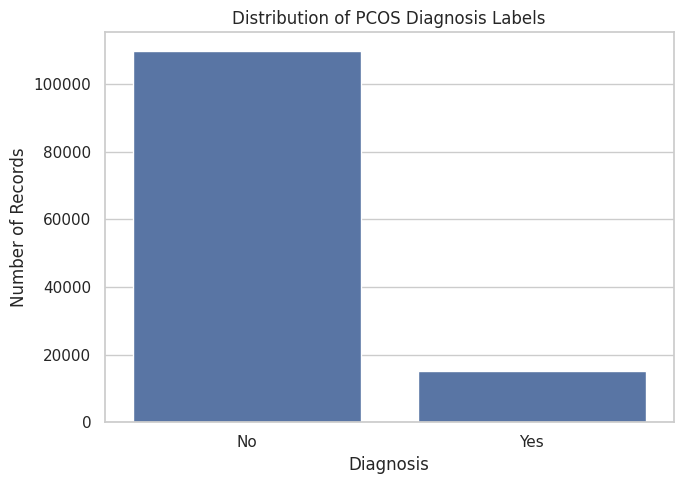

In [18]:
plt.figure(figsize=(7, 5))

sns.countplot(
    data=df,
    x=target_column,
    order=df[target_column].value_counts().index
)

plt.title("Distribution of PCOS Diagnosis Labels")
plt.xlabel("Diagnosis")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

# Step 2 — Exploratory Data Analysis (EDA)

Separate numerical and categorical features

In [19]:
numerical_columns = df.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_columns = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

print("Numerical columns:")
print(numerical_columns)

print("\nCategorical columns:")
print(categorical_columns)

Numerical columns:
['Age', 'Lifestyle Score', 'Undiagnosed PCOS Likelihood']

Categorical columns:
['Country', 'BMI', 'Menstrual Regularity', 'Hirsutism', 'Acne Severity', 'Family History of PCOS', 'Insulin Resistance', 'Stress Levels', 'Urban/Rural', 'Socioeconomic Status', 'Awareness of PCOS', 'Fertility Concerns', 'Ethnicity', 'Diagnosis']


Analyze numerical feature distributions

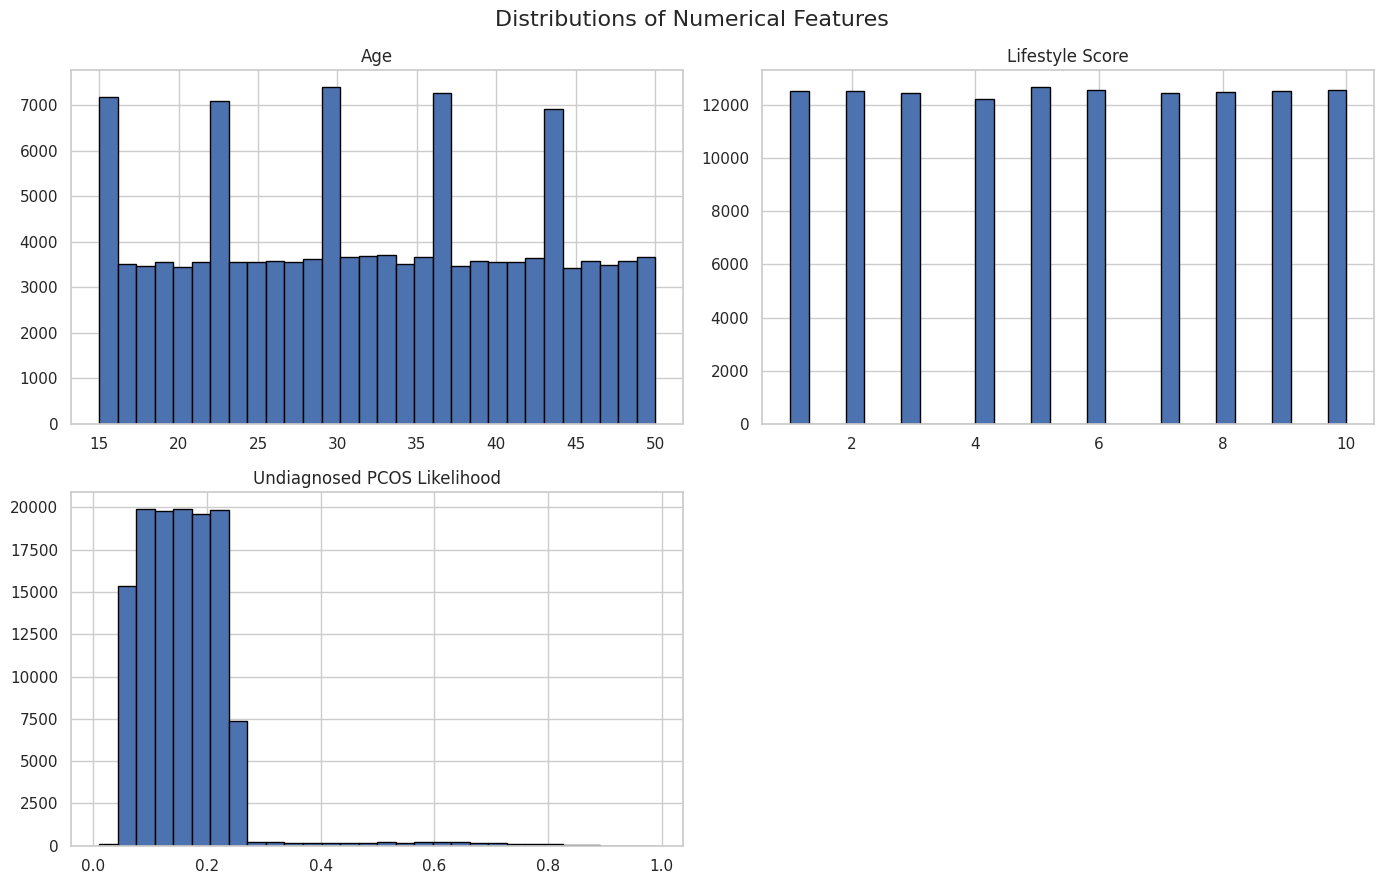

In [20]:
df[numerical_columns].hist(
    figsize=(14, 9),
    bins=30,
    edgecolor="black"
)

plt.suptitle(
    "Distributions of Numerical Features",
    fontsize=16
)

plt.tight_layout()
plt.show()

Inspect numerical statistics by diagnosis

In [21]:
for column in numerical_columns:
    print(f"\n--- {column} by Diagnosis ---")

    print(
        df.groupby(target_column, dropna=False)[column]
        .agg(["count", "mean", "median", "std", "min", "max"])
        .round(3)
    )


--- Age by Diagnosis ---
            count   mean  median    std    min    max
Diagnosis                                            
No         109865 31.973  32.000 10.080 15.000 50.000
Yes         15093 32.233  32.000  9.951 15.000 50.000
NaN             1 25.000  25.000    NaN 25.000 25.000

--- Lifestyle Score by Diagnosis ---
            count  mean  median   std   min    max
Diagnosis                                         
No         109865 5.504   6.000 2.875 1.000 10.000
Yes         15093 5.509   5.000 2.870 1.000 10.000
NaN             1 4.000   4.000   NaN 4.000  4.000

--- Undiagnosed PCOS Likelihood by Diagnosis ---
            count  mean  median   std   min   max
Diagnosis                                        
No         109865 0.151   0.151 0.061 0.010 0.683
Yes         15093 0.222   0.168 0.181 0.050 0.988
NaN             1 0.142   0.142   NaN 0.142 0.142


Analyze categorical feature frequencies

In [22]:
for column in categorical_columns:
    print(f"\n--- {column} ---")
    print(df[column].value_counts(dropna=False))


--- Country ---
Country
Burkina Faso      1750
Vietnam           1703
Ghana             1699
Malawi            1692
South Korea       1689
South Africa      1685
Philippines       1684
Canada            1684
Ethiopia          1680
France            1673
Peru              1672
Chile             1668
Indonesia         1666
Kenya             1665
Spain             1665
Senegal           1664
India             1663
Yemen             1662
Argentina         1660
Romania           1653
Colombia          1650
United States     1649
Mali              1648
Pakistan          1647
Japan             1642
Italy             1641
Ecuador           1637
Germany           1635
Brazil            1635
Russia            1635
Ivory Coast       1632
Kazakhstan        1631
Iran              1631
Mexico            1630
Madagascar        1630
Angola            1630
Burundi           1628
Morocco           1621
China             1620
Ukraine           1619
Chad              1619
Myanmar           1617
Afghanist

Compare categorical features with diagnosis

In [23]:
categorical_features = [
    "BMI",
    "Menstrual Regularity",
    "Hirsutism",
    "Acne Severity",
    "Family History of PCOS",
    "Insulin Resistance",
    "Stress Levels",
    "Fertility Concerns"
]

for column in categorical_features:
    print(f"\n--- {column} ---")

    counts = pd.crosstab(
        df[column],
        df[target_column],
        dropna=False
    )

    row_percentages = pd.crosstab(
        df[column],
        df[target_column],
        normalize="index",
        dropna=False
    ).mul(100)

    print("Counts:")
    print(counts)

    print("\nPercentage within each category:")
    print(row_percentages.round(2))


--- BMI ---
Counts:
Diagnosis       No   Yes  NaN
BMI                          
Normal       55088  7484    1
Obese        16371  2261    0
Overweight   33022  4536    0
Underweight   5384   812    0

Percentage within each category:
Diagnosis       No    Yes   NaN
BMI                            
Normal      88.040 11.960 0.000
Obese       87.860 12.140 0.000
Overweight  87.920 12.080 0.000
Underweight 86.890 13.110 0.000

--- Menstrual Regularity ---
Counts:
Diagnosis                No   Yes  NaN
Menstrual Regularity                  
Irregular             32652  5392    0
Regular               77213  9701    1

Percentage within each category:
Diagnosis                No    Yes   NaN
Menstrual Regularity                    
Irregular            85.830 14.170 0.000
Regular              88.840 11.160 0.000

--- Hirsutism ---
Counts:
Diagnosis     No   Yes  NaN
Hirsutism                  
No         66302  8403    1
Yes        43563  6690    0

Percentage within each category:
Diagnosi

Visualize important categorical features

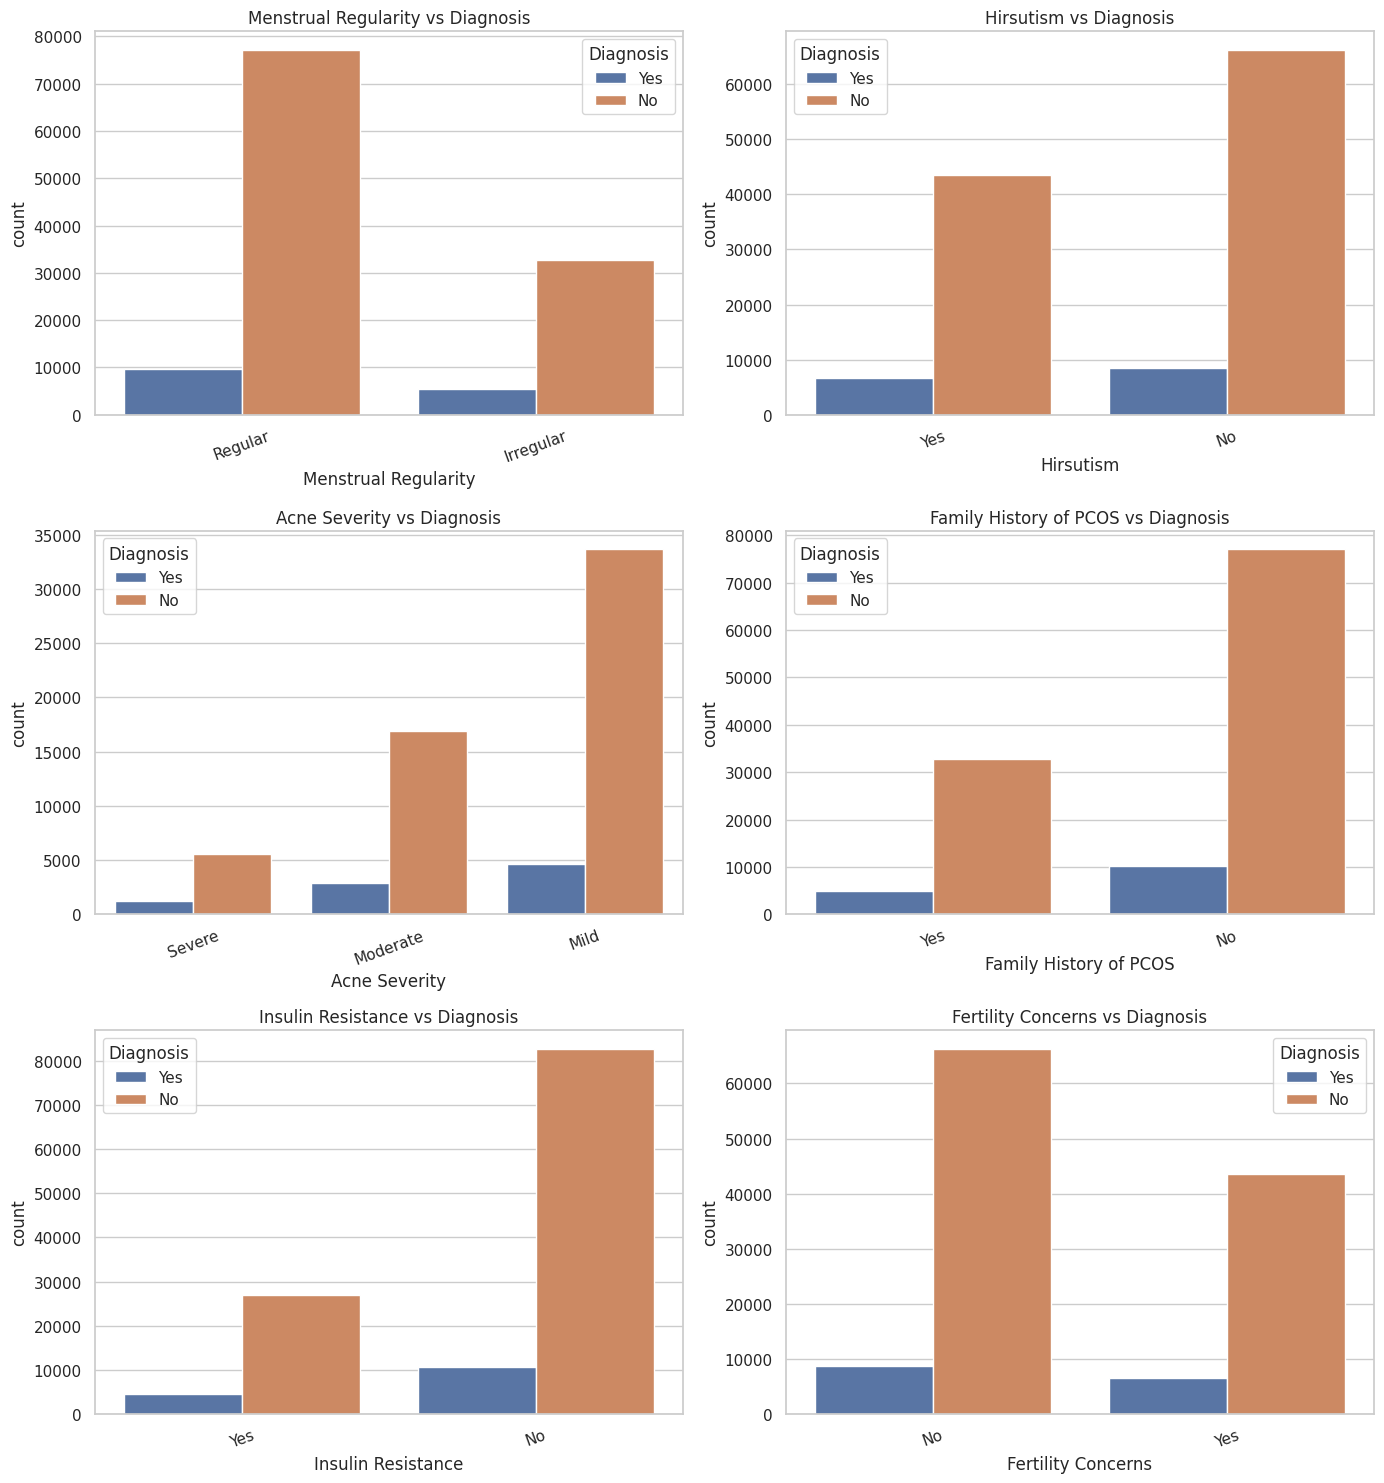

In [24]:
features_to_plot = [
    "Menstrual Regularity",
    "Hirsutism",
    "Acne Severity",
    "Family History of PCOS",
    "Insulin Resistance",
    "Fertility Concerns"
]

fig, axes = plt.subplots(3, 2, figsize=(14, 15))

for ax, column in zip(axes.flatten(), features_to_plot):
    sns.countplot(
        data=df,
        x=column,
        hue="Diagnosis",
        ax=ax
    )

    ax.set_title(f"{column} vs Diagnosis")
    ax.tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

Plot the correlation matrix for numerical columns

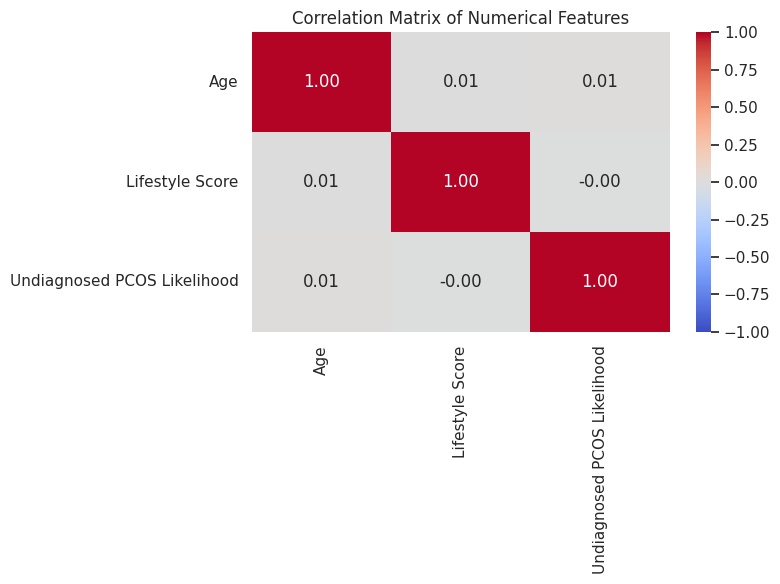

In [25]:
correlation_columns = [
    "Age",
    "Lifestyle Score",
    "Undiagnosed PCOS Likelihood"
]

correlation_matrix = df[correlation_columns].corr()

plt.figure(figsize=(8, 6))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix of Numerical Features")
plt.tight_layout()
plt.show()

Investigate missing acne values

In [26]:
df["Acne Missing"] = df["Acne Severity"].isna()

acne_missing_summary = pd.crosstab(
    df["Diagnosis"],
    df["Acne Missing"],
    normalize="index"
).mul(100)

print("Percentage of acne values missing within each diagnosis group:")
print(acne_missing_summary.round(2))

Percentage of acne values missing within each diagnosis group:
Acne Missing  False  True 
Diagnosis                 
No           51.050 48.950
Yes          58.210 41.790


Investigate the likelihood score

Overall likelihood score summary:
count   124959.000
mean         0.160
std          0.088
min          0.010
25%          0.101
50%          0.153
75%          0.204
max          0.988
Name: Undiagnosed PCOS Likelihood, dtype: float64

Likelihood score by diagnosis:
            count  mean   std   min  median   max
Diagnosis                                        
No         109865 0.151 0.061 0.010   0.151 0.683
Yes         15093 0.223 0.181 0.050   0.169 0.989


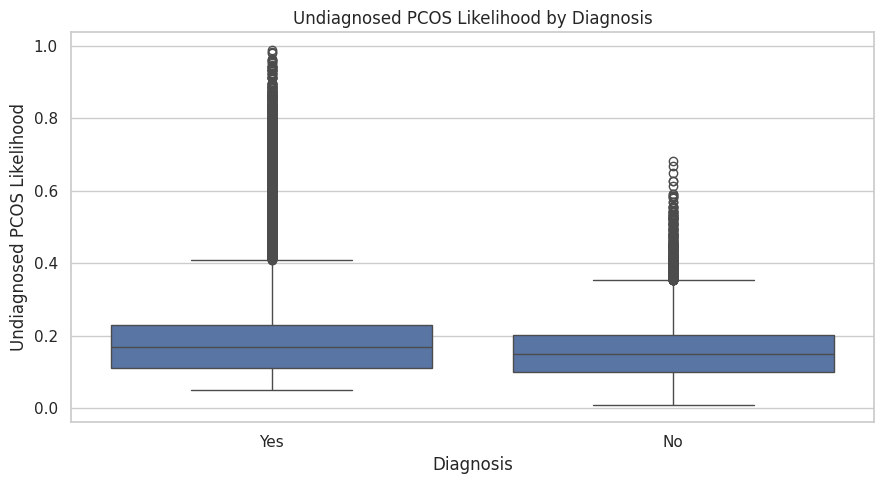

In [27]:
score_column = "Undiagnosed PCOS Likelihood"

print("Overall likelihood score summary:")
print(df[score_column].describe())

print("\nLikelihood score by diagnosis:")
print(
    df.groupby("Diagnosis")[score_column]
    .agg(["count", "mean", "std", "min", "median", "max"])
    .round(4)
)

plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Diagnosis",
    y=score_column
)

plt.title("Undiagnosed PCOS Likelihood by Diagnosis")
plt.tight_layout()
plt.show()

Explore age by diagnosis

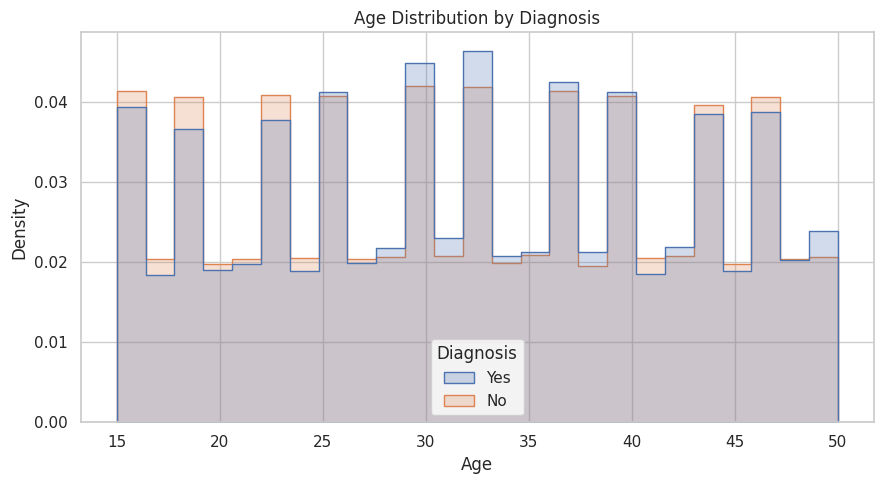

In [28]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Age",
    hue="Diagnosis",
    bins=25,
    stat="density",
    common_norm=False,
    element="step"
)

plt.title("Age Distribution by Diagnosis")
plt.xlabel("Age")
plt.ylabel("Density")
plt.tight_layout()
plt.show()

Summarize diagnosis rates for categorical features

In [29]:
for column in categorical_features:
    summary = (
        df.groupby(column, dropna=False)["Diagnosis"]
        .apply(lambda values: (values == "Yes").mean() * 100)
        .rename("Diagnosis Yes (%)")
        .to_frame()
    )

    print(f"\n--- {column} ---")
    print(summary.round(2))


--- BMI ---
             Diagnosis Yes (%)
BMI                           
Normal                  11.960
Obese                   12.140
Overweight              12.080
Underweight             13.110

--- Menstrual Regularity ---
                      Diagnosis Yes (%)
Menstrual Regularity                   
Irregular                        14.170
Regular                          11.160

--- Hirsutism ---
           Diagnosis Yes (%)
Hirsutism                   
No                    11.250
Yes                   13.310

--- Acne Severity ---
               Diagnosis Yes (%)
Acne Severity                   
Mild                      12.170
Moderate                  14.670
Severe                    18.020
NaN                       10.500

--- Family History of PCOS ---
                        Diagnosis Yes (%)
Family History of PCOS                   
No                                 11.730
Yes                                12.890

--- Insulin Resistance ---
                    Diagnos

# step 3 data pre-processing

Select features and target


In [30]:
df = df.dropna(subset=["Diagnosis"]).copy()

features = [
    "Age",
    "BMI",
    "Menstrual Regularity",
    "Hirsutism",
    "Acne Severity",
    "Family History of PCOS",
    "Insulin Resistance",
    "Lifestyle Score",
    "Stress Levels",
    "Fertility Concerns"
]

X = df[features]
y = df["Diagnosis"].map({"No": 0, "Yes": 1})

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (124958, 10)
Target shape: (124958,)


Split the dataset

In [31]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (99966, 10)
Testing data: (24992, 10)


Handle missing values and encode categories

Explanation:
- Missing numerical values are filled with the median.
- Missing categorical values are marked as "Not recorded".
- Categories are converted into numerical values.
- Numerical features are standardized.

In [32]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numeric_features = ["Age", "Lifestyle Score"]

categorical_features = [
    "BMI",
    "Menstrual Regularity",
    "Hirsutism",
    "Acne Severity",
    "Family History of PCOS",
    "Insulin Resistance",
    "Stress Levels",
    "Fertility Concerns"
]

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="constant", fill_value="Not recorded"
    )),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
])

print("Preprocessing setup complete!")

Preprocessing setup complete!


# step 4 model training

train all the three models

In [33]:
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ),

    "Linear SVM": LinearSVC(
        class_weight="balanced",
        max_iter=3000,
        random_state=42
    )
}

trained_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", model)
    ])

    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline

    print(f"{name} trained successfully!")

print("\nAll models are ready for evaluation.")

Logistic Regression trained successfully!
Random Forest trained successfully!
Linear SVM trained successfully!

All models are ready for evaluation.


# Step 5: Model Evaluation

compare model performance

In [34]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

results = []

for name, model in trained_models.items():
    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, zero_division=0)
    })

results_df = pd.DataFrame(results)

display(
    results_df.sort_values("F1-Score", ascending=False)
    .round(4)
)

,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.580,0.141,0.485,0.218
2,Linear SVM,0.581,0.141,0.483,0.218
1,Random Forest,0.807,0.133,0.107,0.118


Visualize the comparison

**Explanation**: This graph helps us compare the models across multiple metrics. We should not automatically choose the model with the highest accuracy; recall, precision, and F1-score also matter.

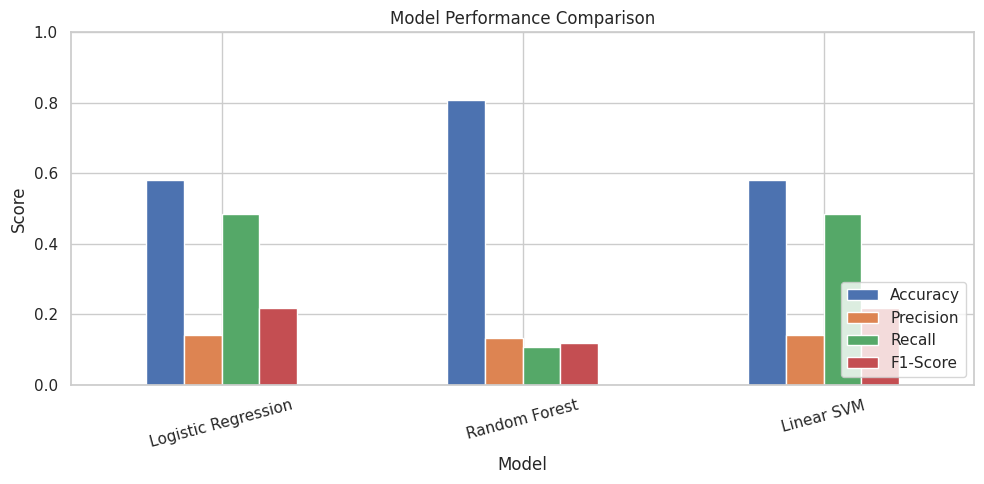

In [35]:
results_plot = results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1-Score"]
]

results_plot.plot(kind="bar", figsize=(10, 5))

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

Confusion matrix for the best model
Explanation: The confusion matrix shows correct and incorrect predictions:
- True Negative: Correctly predicted No.
- True Positive: Correctly predicted Yes.
- False Positive: Predicted Yes when the dataset label is No.
- False Negative: Predicted No when the dataset label is Yes.

Best model by F1-score: Logistic Regression


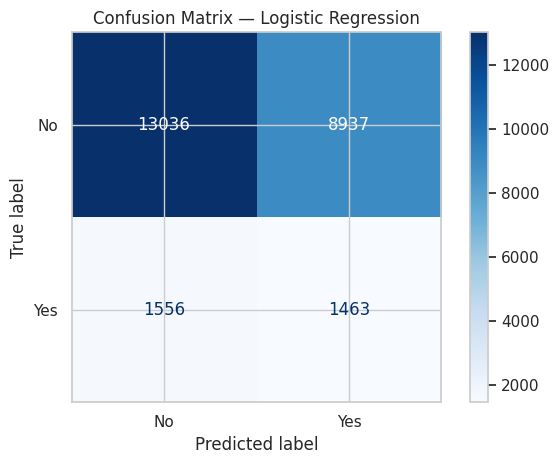

In [36]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

best_name = results_df.sort_values(
    "F1-Score", ascending=False
).iloc[0]["Model"]

best_model = trained_models[best_name]
y_pred = best_model.predict(X_test)

print("Best model by F1-score:", best_name)

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No", "Yes"]
)

display.plot(cmap="Blues")
plt.title(f"Confusion Matrix — {best_name}")
plt.tight_layout()
plt.show()

In [37]:
import joblib

svm_model = trained_models["Linear SVM"]

joblib.dump(svm_model, "femai_svm_model.pkl")

print("SVM model saved successfully!")

SVM model saved successfully!


In [38]:
import pandas as pd

sample = pd.DataFrame([{
    "Age": 25,
    "BMI": "Overweight",
    "Menstrual Regularity": "Irregular",
    "Hirsutism": "Yes",
    "Acne Severity": "Moderate",
    "Family History of PCOS": "No",
    "Insulin Resistance": "No",
    "Lifestyle Score": 5,
    "Stress Levels": "High",
    "Fertility Concerns": "Yes"
}])

prediction = svm_model.predict(sample)[0]

if prediction == 1:
    print("Model prediction: Positive")
else:
    print("Model prediction: Negative")

Model prediction: Positive


In [39]:
decision_score = svm_model.decision_function(sample)[0]

print("Prediction:", "Positive" if prediction == 1 else "Negative")
print("SVM decision score:", round(decision_score, 4))

Prediction: Positive
SVM decision score: 0.2662
